In [1]:
import json
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf 
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

DATA = Path("/home/lynea/Documents/python/WQD7001/data/processed")
df = pd.read_parquet(DATA / "vehicles_clean.parquet")
A = json.load(open(DATA / "assumptions.json"))
PRICE = A["PRICE_MYR"]

PT = ["ICE", "MHEV", "HEV", "PHEV", "BEV"]
PT_COLORS = {"ICE": "#2a78d6", "MHEV": "#eb6834", "HEV": "#1baf7a", "PHEV": "#eda100", "BEV": "#e87ba4"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]                      
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])     

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "font.size": 10, "lines.linewidth": 2, "figure.dpi": 100,
})

df_full = df.copy()                                         # full data
df_full["powertrain"] = pd.Categorical(df_full["powertrain"].astype(str), categories=PT, ordered=True)
df = df[~df["is_energy_outlier"]].copy()                    
df["powertrain"] = pd.Categorical(df["powertrain"].astype(str), categories=PT, ordered=True)
meas = df[~df["consumption_estimated"]].copy()             # measured (EPA) consumption only
print(f"rows: {len(df):,} | measured consumption: {len(meas):,} | estimated (OpenEV-only): {(~df.index.isin(meas.index)).sum():,}")

rows: 15,500 | measured consumption: 15,168 | estimated (OpenEV-only): 332


In [2]:
RESULTS = []


def boot_ci(x, func=np.median, n_boot=2000, seed=0):
    x = np.asarray(x)
    rng = np.random.default_rng(seed)
    b = np.array([func(rng.choice(x, len(x))) for _ in range(n_boot)])
    return np.percentile(b, [2.5, 97.5])

def cliffs_delta(x, y):
    u = stats.mannwhitneyu(x, y, alternative="two-sided").statistic
    return 2 * u / (len(x) * len(y)) - 1

def delta_label(d):
    d = abs(d)
    return "negligible" if d < 0.147 else "small" if d < 0.33 else "medium" if d < 0.474 else "large"

def kruskal_eps2(groups):
    h, p = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    return h, p, h / (n - 1)

def pairwise_mwu(data, value, group, order):
    rows = []
    for a, b in combinations([g for g in order if (data[group] == g).any()], 2):
        x, y = data.loc[data[group] == a, value].dropna(), data.loc[data[group] == b, value].dropna()
        rows.append({"A": a, "B": b, "median_A": x.median(), "median_B": y.median(),
                     "p_raw": stats.mannwhitneyu(x, y).pvalue, "cliffs_delta": cliffs_delta(x, y)})
    out = pd.DataFrame(rows)
    out["p_holm"] = multipletests(out["p_raw"], method="holm")[1]
    out["magnitude"] = out["cliffs_delta"].map(delta_label)
    return out

def cramers_v(ct):
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    return chi2, p, dof, np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

## 1. Dataset overview


In [3]:
comp_table = pd.crosstab(df["powertrain"], df["source"], margins=True, margins_name="Total")
comp_table

source,OpenEV,fueleconomy.gov,fueleconomy.gov + OpenEV,Total
powertrain,,,,
ICE,0,11962,0,11962
MHEV,0,785,0,785
HEV,0,645,0,645
PHEV,0,424,0,424
BEV,332,375,977,1684
Total,332,14191,977,15500


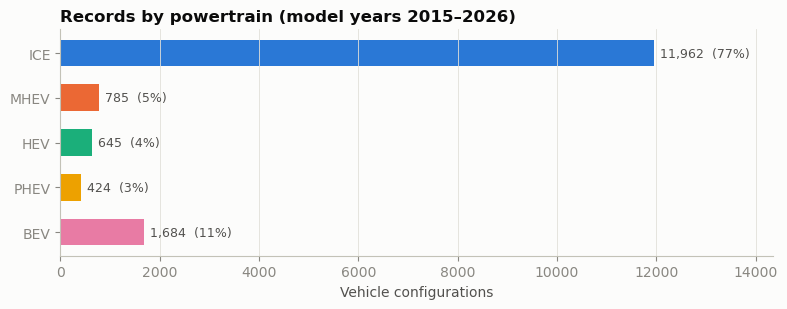

In [4]:
counts = df["powertrain"].value_counts().reindex(PT)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(counts.index[::-1], counts.values[::-1], color=[PT_COLORS[p] for p in counts.index[::-1]], height=0.6)
for i, v in enumerate(counts.values[::-1]):
    ax.text(v + 120, i, f"{v:,}  ({v / counts.sum():.0%})", va="center", color=INK2, fontsize=9)
ax.set(xlabel="Vehicle configurations", title="Records by powertrain (model years 2015–2026)")
ax.grid(axis="y", visible=False); ax.set_xlim(0, counts.max() * 1.2)
plt.tight_layout(); plt.show()

Well obviously ICE is the majority since there is not alot of EV and Hybrid models

In [5]:
df.describe()

,year,match_year_gap,n_gears,engine_displacement_l,engine_cylinders,battery_voltage,power_kw,torque_nm,accel_0_100_s,top_speed_kmh,fuel_l_100km_city,fuel_l_100km_hwy,fuel_l_100km_comb,elec_kwh_100km_city,elec_kwh_100km_hwy,elec_kwh_100km_comb,energy_kwh_100km,mpg_or_mpge_comb,co2_g_km,epa_fe_score,epa_ghg_score,range_km,range_wltp_km,usable_range_km,phev_elec_range_km,phev_utility_factor,battery_net_kwh,battery_gross_kwh,dc_max_kw,ac_max_kw,dc_c_rate,charge_time_240v_h,dc_10_80_min_est,km_per_charge_min,cost_myr_100km,annual_cost_myr,annual_fuel_cost_usd,energy_robust_z
count,"15,500.000",977.000,"14,106.000","13,817.000","13,816.000","1,258.000","2,093.000","1,106.000","1,178.000","1,190.000","13,816.000","13,816.000","13,816.000","1,776.000","1,776.000","2,108.000","15,500.000","15,168.000","15,500.000","15,168.000","15,168.000","1,684.000",935.000,"1,684.000",424.000,424.000,"1,242.000","1,242.000","1,239.000","1,309.000","1,239.000","1,775.000","1,239.000","1,239.000","15,500.000","15,500.000","15,168.000","15,500.000"
mean,"2,020.557",0.368,6.743,3.065,5.516,141.376,286.016,678.333,5.288,199.091,12.049,8.978,10.669,24.438,25.958,24.615,86.672,29.783,220.722,5.217,5.283,429.674,506.860,300.771,43.361,0.516,88.995,93.942,191.328,11.749,2.194,8.725,29.930,11.502,39.904,"7,980.809","3,206.385",0.123
std,3.419,0.483,2.470,1.280,1.783,108.401,190.186,354.274,2.236,38.978,3.076,1.981,2.540,7.652,6.303,6.613,31.393,21.752,97.690,2.047,2.184,117.052,108.948,81.936,28.180,0.149,29.691,31.216,68.798,3.265,0.672,3.908,9.202,4.917,13.360,"2,672.017","1,176.609",0.965
min,"2,015.000",0.000,1.000,0.000,2.000,12.000,6.000,40.000,1.890,45.000,4.055,3.920,3.987,13.440,14.780,11.913,11.913,13.000,0.000,1.000,1.000,57.941,75.000,40.559,1.609,0.184,5.400,5.500,30.000,2.300,0.806,1.100,13.636,2.273,8.399,"1,679.725",500.000,-2.644
25%,"2,018.000",0.000,6.000,2.000,4.000,48.000,135.000,360.000,3.700,180.000,9.801,7.588,9.047,18.814,21.290,19.951,72.218,19.000,188.897,4.000,4.000,365.321,446.000,255.725,27.359,0.411,72.000,77.000,150.000,11.000,1.707,5.000,23.565,8.658,31.922,"6,384.396","2,600.000",-0.657
50%,"2,021.000",0.000,8.000,3.000,6.000,48.000,239.000,615.000,4.600,200.000,11.761,8.712,10.692,22.982,24.756,23.059,91.058,23.000,236.742,5.000,5.000,434.523,513.000,304.166,35.406,0.518,83.700,90.000,195.000,11.000,2.000,9.500,30.000,10.364,40.628,"8,125.595","3,300.000",0.000
75%,"2,024.000",1.000,8.000,3.600,6.000,259.000,400.000,900.000,6.500,210.000,13.836,10.227,12.380,27.340,29.104,27.331,107.572,28.000,282.724,6.000,6.000,494.743,590.000,346.320,53.108,0.620,102.000,108.000,220.000,11.500,2.546,12.000,35.155,13.389,49.395,"9,879.013","3,950.000",0.674
max,"2,026.000",1.000,10.000,8.400,12.000,374.000,"1,417.000","2,300.000",19.100,350.000,23.521,16.801,18.093,55.923,50.952,53.438,161.102,146.000,440.552,10.000,10.000,836.859,850.000,585.801,202.777,0.920,200.000,212.000,402.000,22.000,4.400,18.600,74.400,30.020,75.992,"15,198.481","6,300.000",3.238


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15500 entries, 0 to 15608
Data columns (total 67 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   vehicle_id              15500 non-null  object  
 1   source                  15500 non-null  category
 2   year                    15500 non-null  int64   
 3   make                    15500 non-null  category
 4   model                   15500 non-null  object  
 5   base_model              15168 non-null  object  
 6   trim                    332 non-null    object  
 7   oe_unique_code          1309 non-null   object  
 8   match_confidence        977 non-null    category
 9   match_year_gap          977 non-null    float64 
 10  consumption_estimated   15500 non-null  boolean 
 11  range_epa_is_estimated  15500 non-null  boolean 
 12  powertrain              15500 non-null  category
 13  fuel_grade              15500 non-null  category
 14  fuel_family             155

In [7]:
missing = df.isna().sum()
print(missing[missing > 0])

base_model                 332
trim                     15168
oe_unique_code           14191
match_confidence         14523
match_year_gap           14523
flex_fuel                  332
epa_vehicle_class          332
n_gears                   1394
engine_displacement_l     1683
engine_cylinders          1684
turbo                      332
supercharger               332
start_stop                 332
battery_voltage          14242
power_kw                 13407
torque_nm                14394
accel_0_100_s            14322
top_speed_kmh            14310
fuel_l_100km_city         1684
fuel_l_100km_hwy          1684
fuel_l_100km_comb         1684
elec_kwh_100km_city      13724
elec_kwh_100km_hwy       13724
elec_kwh_100km_comb      13392
mpg_or_mpge_comb           332
epa_fe_score               332
epa_ghg_score              332
gas_guzzler                332
range_km                 13816
range_wltp_km            14565
usable_range_km          13816
phev_elec_range_km       15076
phev_uti

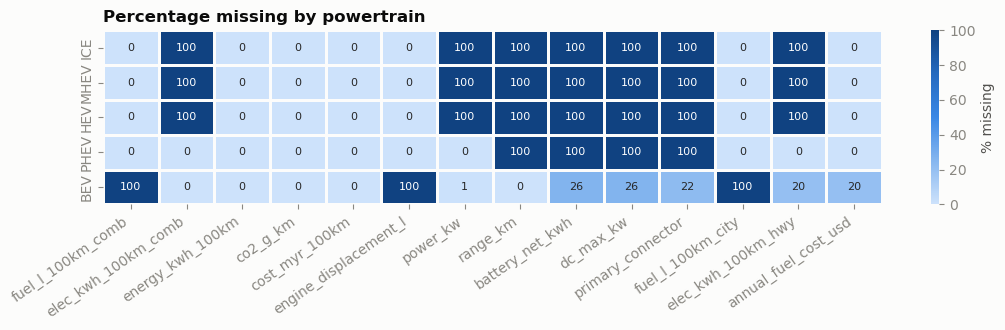

In [8]:
key = ["fuel_l_100km_comb", "elec_kwh_100km_comb", "energy_kwh_100km", "co2_g_km", "cost_myr_100km",
       "engine_displacement_l", "power_kw", "range_km", "battery_net_kwh", "dc_max_kw", "primary_connector",
       "fuel_l_100km_city", "elec_kwh_100km_hwy", "annual_fuel_cost_usd"]
miss = df.groupby("powertrain", observed=True)[key].apply(lambda g: g.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(miss, cmap=SEQ, vmin=0, vmax=100, annot=True, fmt=".0f", linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "% missing"}, ax=ax, annot_kws={"fontsize": 8})
ax.set(title="Percentage missing by powertrain", xlabel="", ylabel=""); ax.grid(False)
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

* `annual_fuel_cost_usd` and the city/highway split are missing only for OpenEV-only EVs, which have no EPA test.
* Battery and DC-charging data exist for ~73 % of BEVs. The rest are US EVs from makes that OpenEV does not cover (Kia, GMC, ...) or EVs older than 2022.
* Every powertrain has complete **energy, CO₂ and cost** values

In [9]:
def describe_plus(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"n": len(s), "mean": s.mean(), "sd": s.std(), "median": s.median(), "IQR": q3 - q1,
                      "min": s.min(), "max": s.max(), "CV_%": s.std() / s.mean() * 100 if s.mean() else np.nan,
                      "skew": stats.skew(s) if s.std() else np.nan,
                      "excess_kurtosis": stats.kurtosis(s) if s.std() else np.nan})

for col, label in [("energy_kwh_100km", "Energy intensity (kWh/100 km)"), ("cost_myr_100km", "Running cost (MYR/100 km)"),
                   ("co2_g_km", "Tailpipe CO2 (g/km)")]:
    print(f"\n{label}")
    display(df.groupby("powertrain", observed=True)[col].apply(describe_plus).unstack().round(2))


Energy intensity (kWh/100 km)


,n,mean,sd,median,IQR,min,max,CV_%,skew,excess_kurtosis
powertrain,,,,,,,,,,
ICE,"11,962.000",97.670,21.270,95.200,29.680,53.700,161.100,21.780,0.470,-0.260
MHEV,785.000,94.220,17.280,91.060,24.170,49.870,139.620,18.340,0.530,-0.170
HEV,645.000,60.000,17.930,55.110,24.280,35.500,110.230,29.890,0.990,0.260
PHEV,424.000,57.270,20.490,55.400,30.500,23.150,113.210,35.770,0.380,-0.520
BEV,"1,684.000",22.660,3.990,22.080,5.890,11.910,34.960,17.600,0.420,-0.300



Running cost (MYR/100 km)


,n,mean,sd,median,IQR,min,max,CV_%,skew,excess_kurtosis
powertrain,,,,,,,,,,
ICE,"11,962.000",44.080,10.290,42.950,15.410,22.920,75.990,23.350,0.490,-0.070
MHEV,785.000,43.960,8.170,42.950,11.400,21.280,65.860,18.580,0.560,0.110
HEV,645.000,26.240,8.470,23.520,12.620,15.150,51.990,32.260,1.010,0.270
PHEV,424.000,30.410,10.060,30.160,14.990,13.070,54.900,33.090,0.230,-0.740
BEV,"1,684.000",15.980,2.810,15.570,4.150,8.400,24.650,17.600,0.420,-0.300



Tailpipe CO2 (g/km)


,n,mean,sd,median,IQR,min,max,CV_%,skew,excess_kurtosis
powertrain,,,,,,,,,,
ICE,"11,962.000",257.260,55.870,251.660,78.910,139.810,440.550,21.720,0.440,-0.320
MHEV,785.000,247.670,45.760,244.200,66.490,129.870,377.790,18.480,0.490,-0.270
HEV,645.000,157.620,46.890,144.780,63.380,93.830,298.260,29.750,0.970,0.220
PHEV,424.000,112.730,58.060,103.770,81.090,13.670,301.990,51.500,0.750,0.210
BEV,"1,684.000",0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN


## NOTE: Energy Intensity is in Kwh/100km not L/100km

Fuel |  kWh per litre   |                                             Source                                                

Petrol | 8.90        |   EPA's MPGe definition: 33.705 kWh per US gallon ÷ 3.785 L                                           

Diesel | 10.06        |  1 gallon of diesel ≈ 1.13 gallons of petrol equivalent (US DOE Alternative Fuels Data Center, AFDC) 


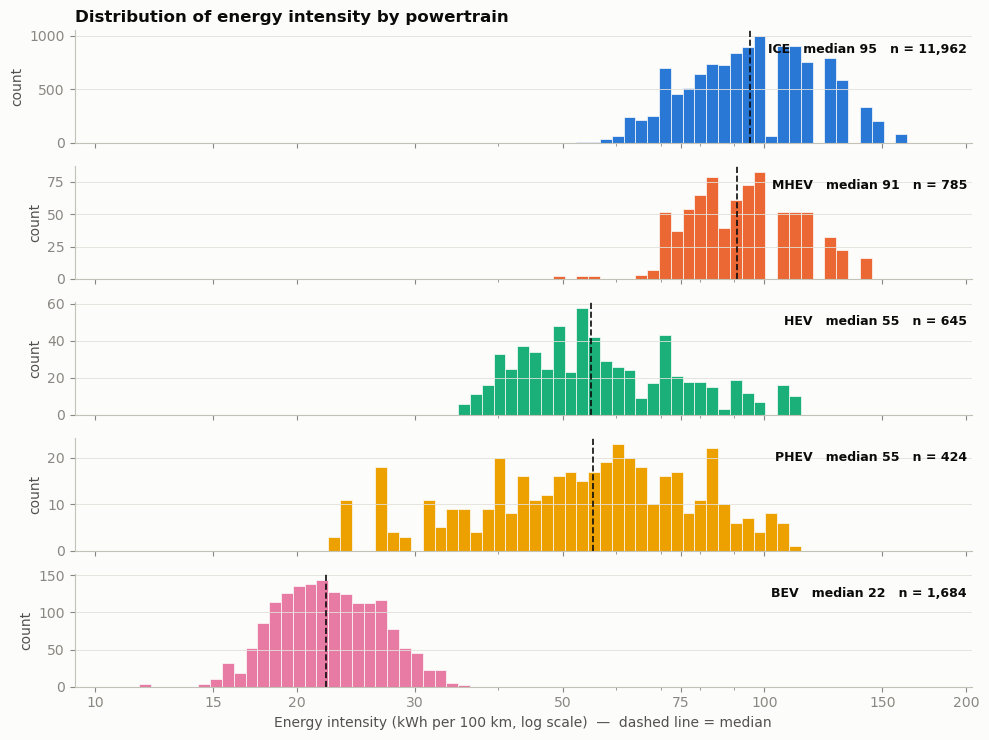

In [10]:
fig, axes = plt.subplots(5, 1, figsize=(10, 7.5), sharex=True)
bins = np.logspace(np.log10(df["energy_kwh_100km"].min() * 0.9), np.log10(df["energy_kwh_100km"].max() * 1.1), 70)
for ax, p in zip(axes, PT):
    x = df.loc[df["powertrain"] == p, "energy_kwh_100km"]
    ax.hist(x, bins=bins, color=PT_COLORS[p], edgecolor="#fcfcfb", linewidth=0.5)
    ax.axvline(x.median(), color=INK, lw=1.2, ls="--")
    ax.text(0.995, 0.8, f"{p}   median {x.median():.0f}   n = {len(x):,}", transform=ax.transAxes, ha="right",
            color=INK, fontsize=9, fontweight="bold")
    ax.set_ylabel("count"); ax.grid(axis="x", visible=False)
axes[-1].set_xscale("log")
axes[-1].xaxis.set_major_formatter(mticker.ScalarFormatter())
axes[-1].set_xticks([10, 15, 20, 30, 50, 75, 100, 150, 200])
axes[-1].set_xlabel("Energy intensity (kWh per 100 km, log scale)  —  dashed line = median")
axes[0].set_title("Distribution of energy intensity by powertrain")
plt.tight_layout(); plt.show()

## Normality Test
I'll do a Shapiro-Wilk and K2 test on normal and log

In [11]:
rows = []
for p in PT:
    for transform, f in [("raw", lambda v: v), ("log", np.log)]:
        x = f(meas.loc[meas["powertrain"] == p, "energy_kwh_100km"].dropna())
        sub = x.sample(min(500, len(x)), random_state=1)
        rows.append({"powertrain": p, "transform": transform, "n": len(x), "skew": stats.skew(x),
                     "shapiro_W": stats.shapiro(sub).statistic, "shapiro_p": stats.shapiro(sub).pvalue,
                     "K2_p": stats.normaltest(x).pvalue})
norm = pd.DataFrame(rows)
norm["normal_at_5%"] = np.where((norm["shapiro_p"] > 0.05) & (norm["K2_p"] > 0.05), "yes", "no")
norm.round(4)

,powertrain,transform,n,skew,shapiro_W,shapiro_p,K2_p,normal_at_5%
0,ICE,raw,11962,0.469,0.975,0.000,0.000,no
1,ICE,log,11962,0.004,0.986,0.000,0.000,no
2,MHEV,raw,785,0.532,0.962,0.000,0.000,no
3,MHEV,log,785,0.092,0.982,0.000,0.202,no
4,HEV,raw,645,0.987,0.912,0.000,0.000,no
5,HEV,log,645,0.488,0.964,0.000,0.000,no
6,PHEV,raw,424,0.377,0.975,0.000,0.000,no
7,PHEV,log,424,-0.344,0.975,0.000,0.000,no
8,BEV,raw,1352,0.316,0.986,0.000,0.000,no
9,BEV,log,1352,-0.038,0.990,0.002,0.000,no


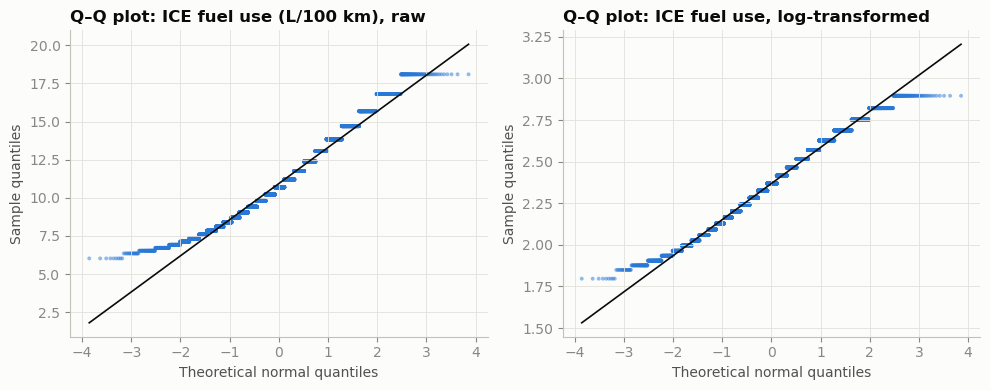

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = meas.loc[meas["powertrain"] == "ICE", "fuel_l_100km_comb"]
for ax, (data, title) in zip(axes, [(x, "ICE fuel use (L/100 km), raw"), (np.log(x), "ICE fuel use, log-transformed")]):
    (osm, osr), (slope, icpt, _) = stats.probplot(data, dist="norm")
    ax.scatter(osm, osr, s=8, color=PT_COLORS["ICE"], alpha=0.5, edgecolor="none")
    ax.plot(osm, slope * osm + icpt, color=INK, lw=1.2)
    ax.set(title=f"Q–Q plot: {title}", xlabel="Theoretical normal quantiles", ylabel="Sample quantiles")
plt.tight_layout(); plt.show()

**Findings**
* Energy intensity is **not normally distributed** in any powertrain group: every Shapiro–Wilk and K² p-value is below 0.05 on the raw scale. The distributions are **right-skewed** (skew 0.4–2.0) because of the high-consumption tail (supercars, large pickups).
* The **log transform removes most of the skew**; for example, ICE skew drops from 0.78 to 0.13 and BEV skew from 1.01 to 0.30. The Q–Q plot becomes almost linear in the body. Formal tests still reject normality on the log scale, but with n in the hundreds or thousands they detect even trivial deviations. The practical conclusion is that **log(consumption)** is the right scale for linear models: coefficients then read as % effects.
* Group comparisons will therefore use **rank-based tests** (Kruskal–Wallis, Mann–Whitney, Wilcoxon). As a robustness check, we confirm key results with Welch's ANOVA on the log scale.

chi2 = 345.0, dof = 16, p = < 0.001, Cramér's V = 0.075


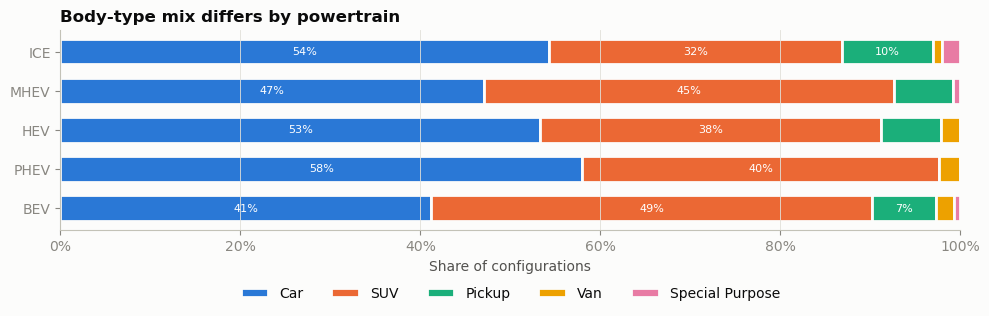

In [13]:
ct = pd.crosstab(df["powertrain"], df["vehicle_class"])
chi2, p, dof, v = cramers_v(ct)
print(f"chi2 = {chi2:,.1f}, dof = {dof}, p = {fmt_p(p)}, Cramér's V = {v:.3f}")


share = ct.div(ct.sum(axis=1), axis=0)
classes = ["Car", "SUV", "Pickup", "Van", "Special Purpose"]
cls_colors = dict(zip(classes, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(share))
for c in classes:
    vals = share[c].reindex(PT).values
    ax.barh(PT[::-1], vals[::-1], left=left[::-1], color=cls_colors[c], edgecolor="#fcfcfb", linewidth=2, label=c, height=0.65)
    for i, (l, w) in enumerate(zip(left[::-1], vals[::-1])):
        if w > 0.07:
            ax.text(l + w / 2, i, f"{w:.0%}", ha="center", va="center", color="#ffffff" if c != "Van" else INK, fontsize=8)
    left += vals
ax.set(xlim=(0, 1), xlabel="Share of configurations", title="Body-type mix differs by powertrain")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1)); ax.grid(axis="y", visible=False)
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()

## CHECKING Trend over the years

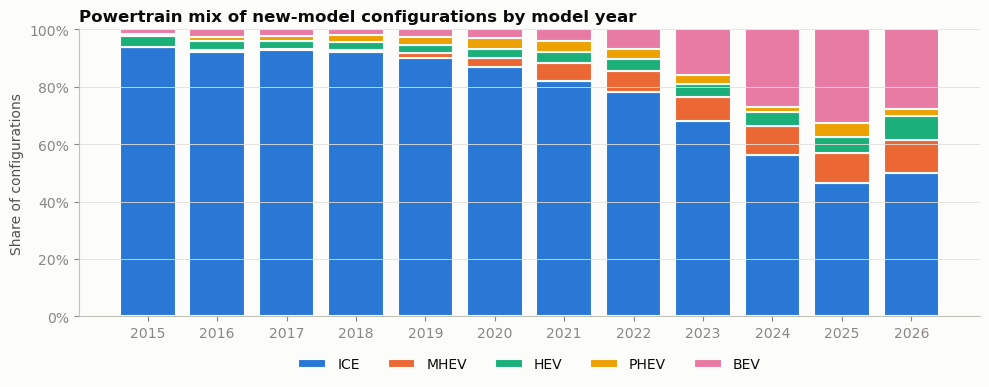

powertrain,ICE,MHEV,HEV,PHEV,BEV
year,,,,,
2015,93.800,0.200,3.600,1.000,1.500
2020,86.800,3.200,3.400,3.600,3.100
2026,50.000,11.500,8.200,2.800,27.600


In [14]:
mix = pd.crosstab(df["year"], df["powertrain"], normalize="index").reindex(columns=PT)
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(mix))
for p in PT:
    ax.bar(mix.index, mix[p], bottom=bottom, color=PT_COLORS[p], edgecolor="#fcfcfb", linewidth=1.5, label=p, width=0.8)
    bottom += mix[p].values
ax.set(ylabel="Share of configurations", title="Powertrain mix of new-model configurations by model year", ylim=(0, 1))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1)); ax.grid(axis="x", visible=False)
ax.set_xticks(mix.index)
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()
(mix.loc[[2015, 2020, 2026]] * 100).round(1)

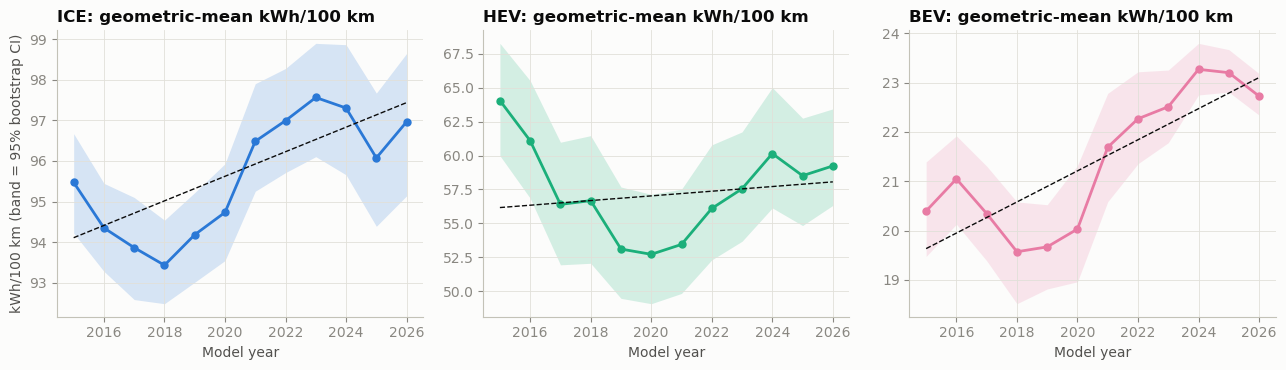

,powertrain,kendall_tau,p_value,theil_sen_slope,slope_95CI,%_per_year
0,ICE,0.485,0.031,0.303,"[0.10, 0.57]",0.316
1,HEV,0.030,0.947,0.172,"[-0.83, 0.81]",0.302
2,BEV,0.576,0.009,0.315,"[0.17, 0.52]",1.475


In [15]:
trend_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, p in zip(axes, ["ICE", "HEV", "BEV"]):
    g = meas[meas["powertrain"] == p]
    gmean = lambda v: float(np.exp(np.mean(np.log(v))))
    yearly = g.groupby("year")["energy_kwh_100km"].agg(gmean)
    ci = np.array([boot_ci(g.loc[g["year"] == y, "energy_kwh_100km"], func=gmean, n_boot=500) for y in yearly.index])
    tau, p_mk = stats.kendalltau(yearly.index, yearly.values)
    ts = stats.theilslopes(yearly.values, yearly.index)
    trend_rows.append({"powertrain": p, "kendall_tau": tau, "p_value": p_mk, "theil_sen_slope": ts.slope,
                       "slope_95CI": f"[{ts.low_slope:.2f}, {ts.high_slope:.2f}]",
                       "%_per_year": ts.slope / yearly.median() * 100})
    ax.fill_between(yearly.index, ci[:, 0], ci[:, 1], color=PT_COLORS[p], alpha=0.18, linewidth=0)
    ax.plot(yearly.index, yearly.values, color=PT_COLORS[p], marker="o", markersize=5)
    ax.plot(yearly.index, ts.intercept + ts.slope * yearly.index, color=INK, lw=1, ls="--")
    ax.set(title=f"{p}: geometric-mean kWh/100 km", xlabel="Model year")
axes[0].set_ylabel("kWh/100 km (band = 95% bootstrap CI)")
plt.tight_layout(); plt.show()

trends = pd.DataFrame(trend_rows)
trends.round(3)

Efficiency is improving especially in BEV

## Energy Use and Running Cost

In [16]:
groups = [meas.loc[meas["powertrain"] == p, "energy_kwh_100km"].values for p in PT]
lev = stats.levene(*groups, center="median")
H, p_kw, eps2 = kruskal_eps2(groups)
welch = anova_oneway(np.log(meas["energy_kwh_100km"]), meas["powertrain"].astype(str), use_var="unequal")
print(f"Levene (Brown-Forsythe): W = {lev.statistic:.1f}, p = {fmt_p(lev.pvalue)}  -> variances {'differ' if lev.pvalue < 0.05 else 'similar'}")
print(f"Kruskal-Wallis: H = {H:,.1f}, p = {fmt_p(p_kw)}, epsilon^2 = {eps2:.3f}")
print(f"Welch ANOVA (log energy): F = {welch.statistic:,.1f}, p = {fmt_p(welch.pvalue)}")


pw = pairwise_mwu(meas, "energy_kwh_100km", "powertrain", PT)
pw.round(4)

Levene (Brown-Forsythe): W = 405.0, p = < 0.001  -> variances differ
Kruskal-Wallis: H = 5,372.5, p = < 0.001, epsilon^2 = 0.354
Welch ANOVA (log energy): F = 18,989.1, p = < 0.001


,A,B,median_A,median_B,p_raw,cliffs_delta,p_holm,magnitude
0,ICE,MHEV,95.197,91.058,0.000,0.082,0.000,negligible
1,ICE,HEV,95.197,55.114,0.000,0.820,0.000,large
2,ICE,PHEV,95.197,55.395,0.000,0.827,0.000,large
3,ICE,BEV,95.197,22.497,0.000,1.000,0.000,large
4,MHEV,HEV,91.058,55.114,0.000,0.814,0.000,large
5,MHEV,PHEV,91.058,55.395,0.000,0.823,0.000,large
6,MHEV,BEV,91.058,22.497,0.000,1.000,0.000,large
7,HEV,PHEV,55.114,55.395,0.049,0.071,0.049,negligible
8,HEV,BEV,55.114,22.497,0.000,1.000,0.000,large
9,PHEV,BEV,55.395,22.497,0.000,0.950,0.000,large


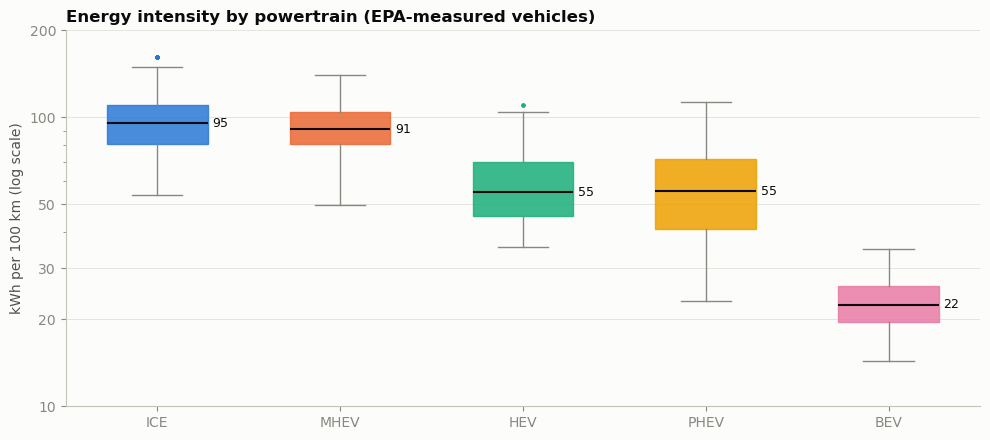

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
data = [meas.loc[meas["powertrain"] == p, "energy_kwh_100km"] for p in PT]
bp = ax.boxplot(data, tick_labels=PT, patch_artist=True, widths=0.55, showfliers=True,
                medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=MUTED, lw=1),
                capprops=dict(color=MUTED, lw=1), flierprops=dict(marker="o", markersize=3, alpha=0.35, markeredgecolor="none"))
for patch, fl, p in zip(bp["boxes"], bp["fliers"], PT):
    patch.set(facecolor=PT_COLORS[p], edgecolor=PT_COLORS[p], alpha=0.85)
    fl.set_markerfacecolor(PT_COLORS[p])
for i, d in enumerate(data, 1):
    ax.text(i + 0.3, np.median(d), f"{np.median(d):.0f}", va="center", fontsize=9, color=INK)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.set_yticks([10, 20, 30, 50, 100, 200])
ax.set(ylabel="kWh per 100 km (log scale)", title="Energy intensity by powertrain (EPA-measured vehicles)")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [18]:
collapsed = (meas.assign(base=meas["base_model"].fillna(meas["model"]))
             .groupby(["make", "base", "powertrain"], observed=True)["energy_kwh_100km"].median().reset_index())
H2, p2, e2 = kruskal_eps2([collapsed.loc[collapsed["powertrain"] == p, "energy_kwh_100km"] for p in PT])
print(f"model-level data: n = {len(collapsed):,} | Kruskal-Wallis H = {H2:,.1f}, p = {fmt_p(p2)}, epsilon^2 = {e2:.3f}")
collapsed.groupby("powertrain", observed=True)["energy_kwh_100km"].agg(["size", "median"]).T

model-level data: n = 807 | Kruskal-Wallis H = 445.2, p = < 0.001, epsilon^2 = 0.552


powertrain,ICE,MHEV,HEV,PHEV,BEV
size,476.000,67.000,76.000,82.000,106.000
median,99.730,83.773,60.142,55.111,22.235


In [19]:
for label, d in [("all rows", df), ("measured only", meas)]:
    H, p_, e = kruskal_eps2([d.loc[d["powertrain"] == p, "cost_myr_100km"] for p in PT])
    print(f"{label:<14s}: Kruskal-Wallis H = {H:,.1f}, p = {fmt_p(p_)}, epsilon^2 = {e:.3f}")


cost_ci = pd.DataFrame({p: {"median": df.loc[df.powertrain == p, "cost_myr_100km"].median(),
                            **dict(zip(["ci_low", "ci_high"], boot_ci(df.loc[df.powertrain == p, "cost_myr_100km"])))}
                        for p in PT}).T
ice_med = cost_ci.loc["ICE", "median"]
cost_ci["vs_ICE_%"] = (cost_ci["median"] / ice_med - 1) * 100
cost_ci["annual_saving_vs_ICE_MYR"] = (ice_med - cost_ci["median"]) * A["ANNUAL_KM"] / 100
cost_ci.round(2)

all rows      : Kruskal-Wallis H = 5,813.1, p = < 0.001, epsilon^2 = 0.375
measured only : Kruskal-Wallis H = 5,069.9, p = < 0.001, epsilon^2 = 0.334


,median,ci_low,ci_high,vs_ICE_%,annual_saving_vs_ICE_MYR
ICE,42.950,42.560,42.950,0.000,0.000
MHEV,42.950,42.560,42.950,0.000,0.000
HEV,23.520,22.920,24.160,-45.240,"3,886.150"
PHEV,30.160,28.930,31.560,-29.780,"2,558.340"
BEV,15.570,15.400,15.770,-63.750,"5,476.700"


In [20]:
pw_cost = pairwise_mwu(df, "cost_myr_100km", "powertrain", PT)
pw_cost.round(4)

,A,B,median_A,median_B,p_raw,cliffs_delta,p_holm,magnitude
0,ICE,MHEV,42.952,42.952,0.696,-0.008,0.696,negligible
1,ICE,HEV,42.952,23.521,0.000,0.818,0.000,large
2,ICE,PHEV,42.952,30.160,0.000,0.644,0.000,large
3,ICE,BEV,42.952,15.569,0.000,1.000,0.000,large
4,MHEV,HEV,42.952,23.521,0.000,0.847,0.000,large
5,MHEV,PHEV,42.952,30.160,0.000,0.696,0.000,large
6,MHEV,BEV,42.952,15.569,0.000,1.000,0.000,large
7,HEV,PHEV,23.521,30.160,0.000,-0.248,0.000,small
8,HEV,BEV,23.521,15.569,0.000,0.844,0.000,large
9,PHEV,BEV,30.160,15.569,0.000,0.834,0.000,large


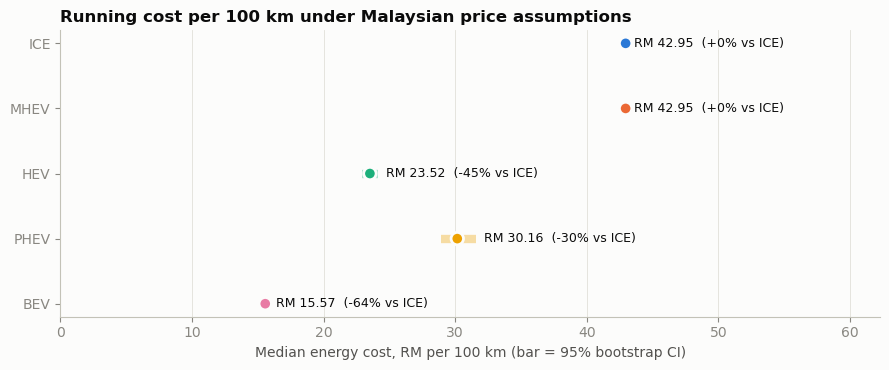

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(PT))[::-1]
ax.hlines(y, cost_ci["ci_low"], cost_ci["ci_high"], color=[PT_COLORS[p] for p in PT], lw=6, alpha=0.35)
ax.scatter(cost_ci["median"], y, s=80, color=[PT_COLORS[p] for p in PT], edgecolor="#fcfcfb", linewidth=2, zorder=3)
for yi, p in zip(y, PT):
    ax.text(cost_ci.loc[p, "ci_high"] + 0.6, yi, f"RM {cost_ci.loc[p, 'median']:.2f}  ({cost_ci.loc[p, 'vs_ICE_%']:+.0f}% vs ICE)",
            va="center", fontsize=9, color=INK)
ax.set_yticks(y, PT); ax.set_xlim(0, cost_ci["ci_high"].max() * 1.45)
ax.set(xlabel="Median energy cost, RM per 100 km (bar = 95% bootstrap CI)",
       title="Running cost per 100 km under Malaysian price assumptions")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Checking Powertrain and Vehicle Size

$$\log(\text{energy}) = \beta_0 + \beta_{\text{powertrain}} + \beta_{\text{class}} + \beta_{\text{drive}} + \beta_{\text{year}}\cdot\text{year} + \varepsilon$$


In [22]:
reg = meas.assign(base=(meas["make"].astype(str) + "|" + meas["base_model"].fillna(meas["model"]).astype(str)),
                  log_energy=np.log(meas["energy_kwh_100km"]),
                  drive=meas["drivetrain"].astype(str).replace({"4WD": "AWD/4WD", "AWD": "AWD/4WD", "2WD": "RWD"}),
                  pt=meas["powertrain"].astype(str), vclass=meas["vehicle_class"].astype(str))
reg = reg.dropna(subset=["log_energy", "drive", "vclass"])
reg = reg[reg["drive"] != "nan"]
m_pt = smf.ols("log_energy ~ C(pt, Treatment('ICE')) + C(vclass, Treatment('Car')) + C(drive, Treatment('FWD')) + year",
               data=reg).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(reg["base"])[0]})
print(f"n = {int(m_pt.nobs):,}, clusters = {reg['base'].nunique():,}, R² = {m_pt.rsquared:.3f}, adj. R² = {m_pt.rsquared_adj:.3f}")

eff = pd.DataFrame({"coef": m_pt.params, "ci_low": m_pt.conf_int()[0], "ci_high": m_pt.conf_int()[1], "p": m_pt.pvalues})
eff = eff.drop("Intercept")
eff["%_effect"] = (np.exp(eff["coef"]) - 1) * 100
eff["%_CI"] = [f"[{(np.exp(l) - 1) * 100:+.1f}, {(np.exp(h) - 1) * 100:+.1f}]" for l, h in zip(eff["ci_low"], eff["ci_high"])]
eff.index = eff.index.str.replace(r"C\((\w+), Treatment\('[\w ]+'\)\)\[T\.", r"\1 = ", regex=True).str.rstrip("]")
eff[["%_effect", "%_CI", "p"]].round(4)

n = 15,168, clusters = 596, R² = 0.867, adj. R² = 0.867


,%_effect,%_CI,p
pt = BEV,-77.085,"[-78.2, -75.9]",0.000
pt = HEV,-35.153,"[-38.4, -31.7]",0.000
pt = MHEV,-6.850,"[-10.8, -2.8]",0.001
pt = PHEV,-43.792,"[-48.7, -38.4]",0.000
vclass = Pickup,17.925,"[+13.1, +23.0]",0.000
vclass = SUV,8.514,"[+5.1, +12.1]",0.000
vclass = Special Purpose,23.506,"[+16.3, +31.2]",0.000
vclass = Van,27.930,"[+19.5, +36.9]",0.000
drive = AWD/4WD,31.071,"[+27.4, +34.8]",0.000
drive = RWD,35.096,"[+30.8, +39.6]",0.000


In [23]:
aov = sm.stats.anova_lm(smf.ols("log_energy ~ C(pt) + C(vclass) + C(drive) + year", data=reg).fit(), typ=2)
aov["partial_eta2"] = aov["sum_sq"] / (aov["sum_sq"] + aov.loc["Residual", "sum_sq"])
aov.round(4)

,sum_sq,df,F,PR(>F),partial_eta2
C(pt),"2,482.663",4.000,"20,526.013",0.000,0.844
C(vclass),53.213,4.000,439.951,0.000,0.104
C(drive),200.122,2.000,"3,309.106",0.000,0.304
year,1.663,1.000,55.002,0.000,0.004
Residual,458.287,"15,156.000",NaN,NaN,0.500


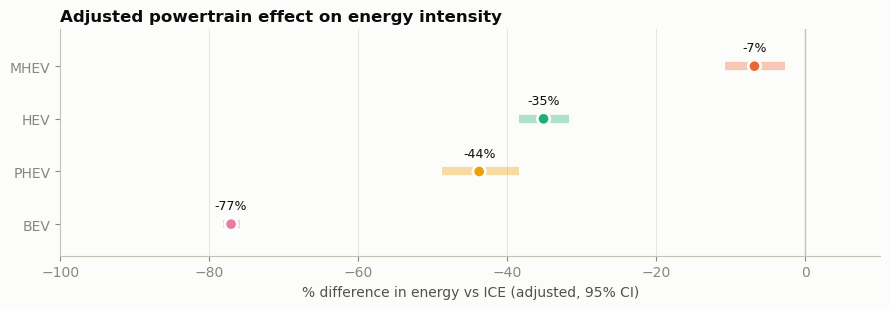

In [24]:
for p in ["MHEV", "HEV", "PHEV", "BEV"]:
    r = eff.loc[f"pt = {p}"]

fig, ax = plt.subplots(figsize=(9, 3.2))
pts = ["MHEV", "HEV", "PHEV", "BEV"]
vals = [eff.loc[f"pt = {p}", "%_effect"] for p in pts]
lo = [(np.exp(eff.loc[f"pt = {p}", "ci_low"]) - 1) * 100 for p in pts]
hi = [(np.exp(eff.loc[f"pt = {p}", "ci_high"]) - 1) * 100 for p in pts]
yy = np.arange(len(pts))[::-1]
ax.hlines(yy, lo, hi, color=[PT_COLORS[p] for p in pts], lw=6, alpha=0.35)
ax.scatter(vals, yy, s=80, color=[PT_COLORS[p] for p in pts], edgecolor="#fcfcfb", linewidth=2, zorder=3)
for yi, v in zip(yy, vals):
    ax.text(v, yi + 0.28, f"{v:+.0f}%", ha="center", fontsize=9, color=INK)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_yticks(yy, pts); ax.set_xlim(-100, 10); ax.set_ylim(-0.6, len(pts) - 0.3)
ax.set(xlabel="% difference in energy vs ICE (adjusted, 95% CI)",
       title="Adjusted powertrain effect on energy intensity")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

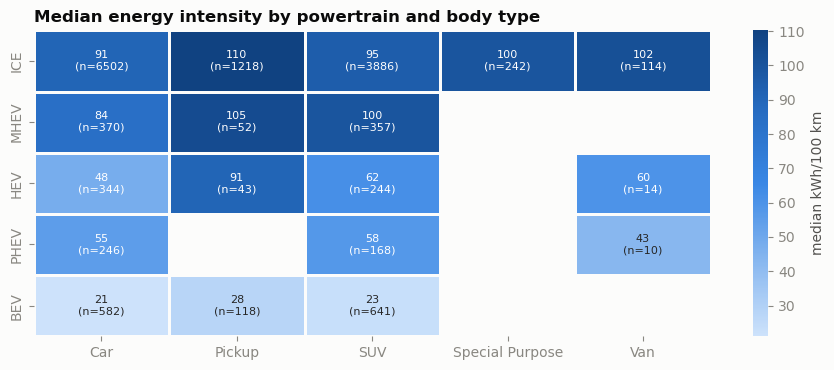

In [25]:
pivot_med = meas.pivot_table(index="powertrain", columns="vehicle_class", values="energy_kwh_100km", aggfunc="median", observed=True)
pivot_n = meas.pivot_table(index="powertrain", columns="vehicle_class", values="energy_kwh_100km", aggfunc="size", observed=True)
masked = pivot_med.where(pivot_n >= 10)
annot = masked.round(0).astype("Int64").astype(str) + "\n(n=" + pivot_n.astype("Int64").astype(str) + ")"
annot = annot.where(masked.notna(), "")
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(masked, annot=annot, fmt="", cmap=SEQ, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "median kWh/100 km"}, ax=ax, annot_kws={"fontsize": 8})
ax.set(title="Median energy intensity by powertrain and body type", xlabel="", ylabel=""); ax.grid(False)
plt.tight_layout(); plt.show()

## Testing Same Model but Different Powertrain

In [26]:
def twins(treat):
    sub = meas[meas["powertrain"].isin(["ICE", treat]) & meas["base_model"].notna()]
    g = (sub.groupby(["make", "base_model", "year", "drivetrain", "powertrain"], observed=True)["fuel_l_100km_comb"]
         .median().unstack("powertrain").dropna())
    g["saving_%"] = (1 - g[treat] / g["ICE"]) * 100
    return g

twin_res = {}
for treat in ["HEV", "MHEV"]:
    g = twins(treat)
    w = stats.wilcoxon(g["ICE"], g[treat])
    n = len(g)
    r_rb = 1 - 2 * w.statistic / (n * (n + 1) / 2)                       # matched-pairs rank-biserial correlation
    ci = boot_ci(g["saving_%"])
    twin_res[treat] = g
    print(f"{treat} vs ICE twins: n pairs = {n} ({g.reset_index()['base_model'].nunique()} models) | "
          f"median saving = {g['saving_%'].median():.1f}% (95% CI {ci[0]:.1f} to {ci[1]:.1f}) | "
          f"Wilcoxon W = {w.statistic:.0f}, p = {fmt_p(w.pvalue)}, rank-biserial r = {r_rb:.2f}")


twin_res["HEV"].reset_index().sort_values("saving_%", ascending=False).drop_duplicates("base_model").head(12)[
    ["make", "base_model", "year", "ICE", "HEV", "saving_%"]].round(2)

HEV vs ICE twins: n pairs = 335 (55 models) | median saving = 28.7% (95% CI 27.1 to 29.9) | Wilcoxon W = 0, p = < 0.001, rank-biserial r = 1.00
MHEV vs ICE twins: n pairs = 162 (39 models) | median saving = 7.1% (95% CI 4.3 to 10.1) | Wilcoxon W = 2512, p = < 0.001, rank-biserial r = 0.62


powertrain,make,base_model,year,ICE,HEV,saving_%
280,Toyota,Corolla,2026,10.250,5.120,50.000
50,Honda,Accord,2017,9.230,4.900,46.900
268,Toyota,Camry,2022,9.050,4.820,46.740
232,Lincoln,MKZ,2020,10.500,5.740,45.370
75,Hyundai,Elantra,2022,7.990,4.530,43.330
163,Lexus,ES,2025,9.410,5.350,43.180
259,Toyota,Avalon,2021,9.410,5.410,42.520
10,Chevrolet,Malibu,2016,8.710,5.110,41.300
102,Hyundai,Sonata,2026,8.110,4.810,40.720
41,Ford,Fusion,2018,9.410,5.600,40.480


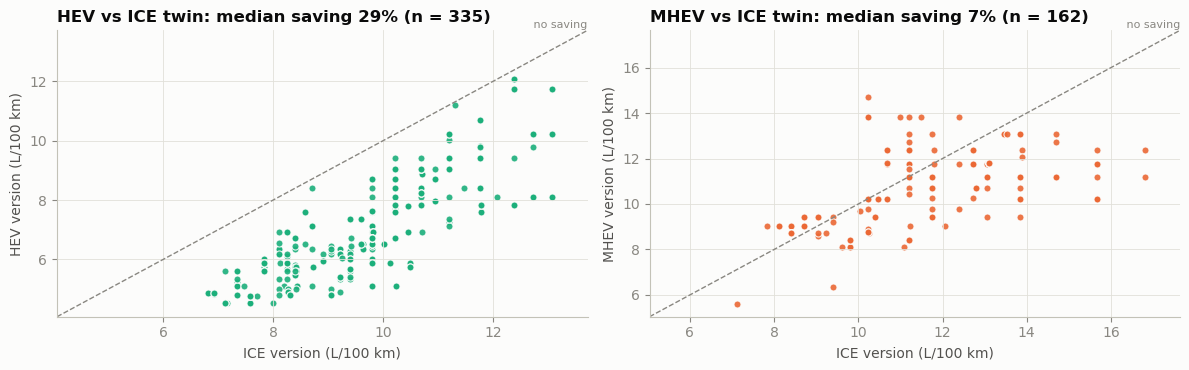

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, treat in zip(axes, ["HEV", "MHEV"]):
    g = twin_res[treat]
    ax.scatter(g["ICE"], g[treat], s=26, color=PT_COLORS[treat], edgecolor="#fcfcfb", linewidth=0.8, alpha=0.9)
    lim = [min(g["ICE"].min(), g[treat].min()) * 0.9, max(g["ICE"].max(), g[treat].max()) * 1.05]
    ax.plot(lim, lim, color=MUTED, ls="--", lw=1)
    ax.text(lim[1], lim[1], " no saving", color=MUTED, fontsize=8, va="bottom", ha="right")
    ax.set(xlim=lim, ylim=lim, xlabel="ICE version (L/100 km)", ylabel=f"{treat} version (L/100 km)",
           title=f"{treat} vs ICE twin: median saving {g['saving_%'].median():.0f}% (n = {len(g)})")
plt.tight_layout(); plt.show()

Above the line means no savings in fuel cost. 

# City vs Highway

In [28]:
cvh = meas.copy()
cvh["city"] = cvh["fuel_l_100km_city"].where(cvh["powertrain"] != "BEV", cvh["elec_kwh_100km_city"])
cvh["hwy"] = cvh["fuel_l_100km_hwy"].where(cvh["powertrain"] != "BEV", cvh["elec_kwh_100km_hwy"])
cvh["city_hwy_ratio"] = cvh["city"] / cvh["hwy"]
rows = []
for p in ["ICE", "MHEV", "HEV", "BEV"]:
    g = cvh[(cvh["powertrain"] == p)].dropna(subset=["city", "hwy"])
    w = stats.wilcoxon(g["city"], g["hwy"])
    rows.append({"powertrain": p, "n": len(g), "median_ratio": g["city_hwy_ratio"].median(),
                 "share_city_better": (g["city_hwy_ratio"] < 1).mean(), "wilcoxon_p": w.pvalue})

cvh_tab = pd.DataFrame(rows)
H, p_, e = kruskal_eps2([cvh.loc[cvh.powertrain == p, "city_hwy_ratio"].dropna() for p in ["ICE", "MHEV", "HEV", "BEV"]])
print(f"Kruskal-Wallis on the ratio across powertrains: H = {H:,.0f}, p = {fmt_p(p_)}, epsilon^2 = {e:.2f}")
cvh_tab.round(4)

Kruskal-Wallis on the ratio across powertrains: H = 5,095, p = < 0.001, epsilon^2 = 0.35


,powertrain,n,median_ratio,share_city_better,wilcoxon_p
0,ICE,11962,1.360,0.001,0.000
1,MHEV,785,1.316,0.008,0.000
2,HEV,645,1.000,0.498,0.765
3,BEV,1352,0.893,0.834,0.000


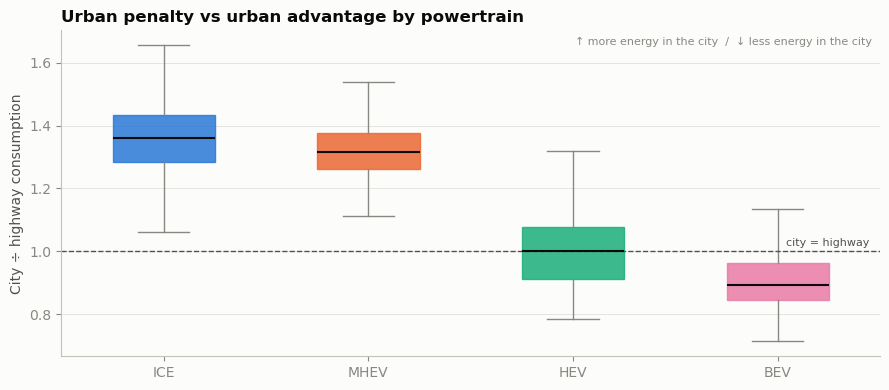

In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
pp = ["ICE", "MHEV", "HEV", "BEV"]
data = [cvh.loc[cvh.powertrain == p, "city_hwy_ratio"].dropna() for p in pp]
bp = ax.boxplot(data, tick_labels=pp, patch_artist=True, widths=0.5, showfliers=False,
                medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, p in zip(bp["boxes"], pp):
    patch.set(facecolor=PT_COLORS[p], edgecolor=PT_COLORS[p], alpha=0.85)
ax.axhline(1, color=INK2, lw=1, ls="--")
ax.text(4.45, 1.01, "city = highway", fontsize=8, color=INK2, ha="right", va="bottom")
ax.text(0.99, 0.98, "↑ more energy in the city  /  ↓ less energy in the city", transform=ax.transAxes, fontsize=8, color=MUTED, va="top", ha="right")
ax.set(ylabel="City ÷ highway consumption", title="Urban penalty vs urban advantage by powertrain")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## Checking Variables that affect Consumption

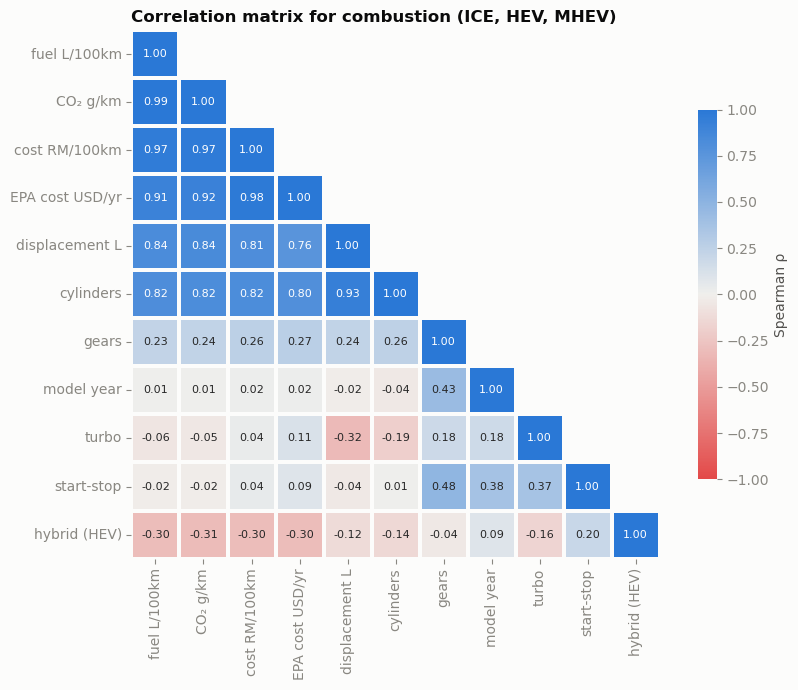

In [30]:
comb_cols = {"fuel_l_100km_comb": "fuel L/100km", "co2_g_km": "CO₂ g/km", "cost_myr_100km": "cost RM/100km",
             "annual_fuel_cost_usd": "EPA cost USD/yr", "engine_displacement_l": "displacement L",
             "engine_cylinders": "cylinders", "n_gears": "gears", "year": "model year", "turbo": "turbo",
             "start_stop": "start-stop", "hybrid": "hybrid (HEV)"}
cb = meas[meas["powertrain"].isin(["ICE", "MHEV", "HEV"])].assign(hybrid=lambda d: d["powertrain"].eq("HEV"))
corr = cb[list(comb_cols)].astype(float).rename(columns=comb_cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap=DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, linewidths=1.5, linecolor="#fcfcfb",
            mask=np.triu(np.ones_like(corr, dtype=bool), 1), cbar_kws={"label": "Spearman ρ", "shrink": 0.7},
            ax=ax, annot_kws={"fontsize": 8})
ax.set_title("Correlation matrix for combustion (ICE, HEV, MHEV)"); ax.grid(False)
plt.tight_layout(); plt.show()

In [31]:
cbr = cb.assign(base=cb["make"].astype(str) + "|" + cb["base_model"].fillna(cb["model"]).astype(str),
                log_fuel=np.log(cb["fuel_l_100km_comb"]), log_displ=np.log(cb["engine_displacement_l"]),
                drive=cb["drivetrain"].astype(str).replace({"4WD": "AWD/4WD", "AWD": "AWD/4WD", "2WD": "RWD"}),
                trans=cb["transmission_type"].astype(str), vclass=cb["vehicle_class"].astype(str),
                pt=cb["powertrain"].astype(str), premium=cb["fuel_grade"].eq("Premium"),
                diesel=cb["fuel_grade"].eq("Diesel"))
for c in ["turbo", "supercharger", "start_stop"]:
    cbr[c] = cbr[c].astype(float)
cbr = cbr.dropna(subset=["log_fuel", "log_displ", "engine_cylinders", "turbo", "start_stop", "trans"])

X_vif = cbr[["log_displ", "engine_cylinders", "turbo", "supercharger", "start_stop", "year"]].astype(float)
X_vif = sm.add_constant(X_vif)
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])], index=X_vif.columns[1:], name="VIF")
print(vif.round(2).to_string())

f_ice = ("log_fuel ~ log_displ + engine_cylinders + turbo + supercharger + start_stop + premium + diesel + year"
         " + C(pt, Treatment('ICE')) + C(vclass, Treatment('Car')) + C(drive, Treatment('FWD')) + C(trans, Treatment('Automatic'))")
m_ice = smf.ols(f_ice, data=cbr).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(cbr["base"])[0]})
print(f"\nn = {int(m_ice.nobs):,}, R² = {m_ice.rsquared:.3f}, adj. R² = {m_ice.rsquared_adj:.3f}")
coefs = pd.DataFrame({"coef": m_ice.params, "p": m_ice.pvalues})
coefs["%_effect"] = np.where(coefs.index == "log_displ", np.nan, (np.exp(coefs["coef"]) - 1) * 100)
coefs.drop("Intercept").round(4)

log_displ          6.870
engine_cylinders   6.290
turbo              1.490
supercharger       1.040
start_stop         1.340
year               1.180

n = 13,392, R² = 0.879, adj. R² = 0.879


,coef,p,%_effect
premium[T.True],0.018,0.027,1.764
diesel[T.True],-0.199,0.000,-18.032
"C(pt, Treatment('ICE'))[T.HEV]",-0.293,0.000,-25.404
"C(pt, Treatment('ICE'))[T.MHEV]",-0.087,0.000,-8.378
"C(vclass, Treatment('Car'))[T.Pickup]",0.128,0.000,13.624
"C(vclass, Treatment('Car'))[T.SUV]",0.102,0.000,10.736
"C(vclass, Treatment('Car'))[T.Special Purpose]",0.206,0.000,22.920
"C(vclass, Treatment('Car'))[T.Van]",0.167,0.000,18.137
"C(drive, Treatment('FWD'))[T.AWD/4WD]",0.082,0.000,8.574
"C(drive, Treatment('FWD'))[T.RWD]",0.065,0.000,6.661


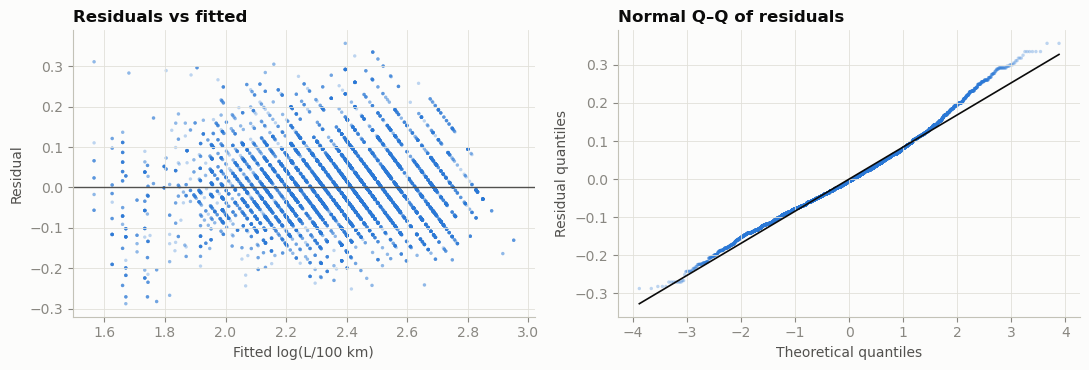

residual skew = 0.42, excess kurtosis = 0.65


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(m_ice.fittedvalues, m_ice.resid, s=6, alpha=0.3, color=PT_COLORS["ICE"], edgecolor="none")
axes[0].axhline(0, color=INK2, lw=1)
axes[0].set(xlabel="Fitted log(L/100 km)", ylabel="Residual", title="Residuals vs fitted")
(osm, osr), (sl, ic, _) = stats.probplot(m_ice.resid, dist="norm")
axes[1].scatter(osm, osr, s=6, alpha=0.3, color=PT_COLORS["ICE"], edgecolor="none")
axes[1].plot(osm, sl * osm + ic, color=INK, lw=1.2)
axes[1].set(xlabel="Theoretical quantiles", ylabel="Residual quantiles", title="Normal Q–Q of residuals")
plt.tight_layout(); plt.show()
print(f"residual skew = {stats.skew(m_ice.resid):.2f}, excess kurtosis = {stats.kurtosis(m_ice.resid):.2f}")

## Same thing but for EV

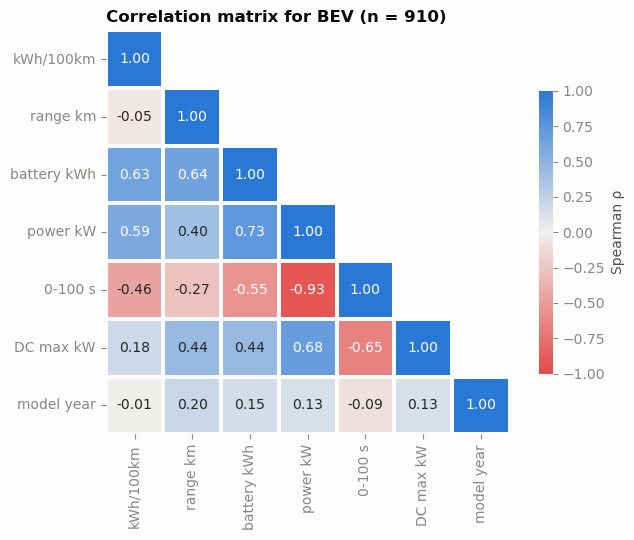

In [33]:
bev = meas[(meas["powertrain"] == "BEV") & meas["battery_net_kwh"].notna() & meas["power_kw"].notna()].copy()
bev_cols = {"elec_kwh_100km_comb": "kWh/100km", "range_km": "range km", "battery_net_kwh": "battery kWh",
            "power_kw": "power kW", "accel_0_100_s": "0-100 s", "dc_max_kw": "DC max kW", "year": "model year"}
corr_b = bev[list(bev_cols)].rename(columns=bev_cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_b, cmap=DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, linewidths=1.5, linecolor="#fcfcfb",
            mask=np.triu(np.ones_like(corr_b, dtype=bool), 1), cbar_kws={"label": "Spearman ρ", "shrink": 0.7}, ax=ax)
ax.set_title(f"Correlation matrix for BEV (n = {len(bev)})"); ax.grid(False)
plt.tight_layout(); plt.show()

In [34]:
bev_r = bev.assign(base=bev["make"].astype(str) + "|" + bev["base_model"].fillna(bev["model"]).astype(str),
                   log_kwh=np.log(bev["elec_kwh_100km_comb"]), log_power=np.log(bev["power_kw"]),
                   vclass=bev["vehicle_class"].astype(str).replace({"Van": "Pickup/Van", "Pickup": "Pickup/Van", "Special Purpose": "Pickup/Van"}),
                   awd=bev["drivetrain"].astype(str).isin(["AWD", "4WD"]).astype(float))
m_bev = smf.ols("log_kwh ~ log_power + battery_net_kwh + awd + year + C(vclass, Treatment('Car'))", data=bev_r).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(bev_r["base"])[0]})
print(f"n = {int(m_bev.nobs)}, models = {bev_r['base'].nunique()}, R² = {m_bev.rsquared:.3f}")
bc = pd.DataFrame({"coef": m_bev.params, "p": m_bev.pvalues, "%_effect": (np.exp(m_bev.params) - 1) * 100}).drop("Intercept")
bc.loc["battery_net_kwh", "%_effect"] = (np.exp(m_bev.params["battery_net_kwh"] * 10) - 1) * 100   # per +10 kWh
bc.rename(index={"battery_net_kwh": "battery_net_kwh (per +10 kWh)"}).round(4)

n = 910, models = 74, R² = 0.473


,coef,p,%_effect
"C(vclass, Treatment('Car'))[T.Pickup/Van]",0.138,0.021,14.775
"C(vclass, Treatment('Car'))[T.SUV]",0.050,0.266,5.158
log_power,0.091,0.067,9.499
battery_net_kwh (per +10 kWh),0.001,0.018,1.407
awd,0.085,0.000,8.825
year,-0.015,0.068,-1.539


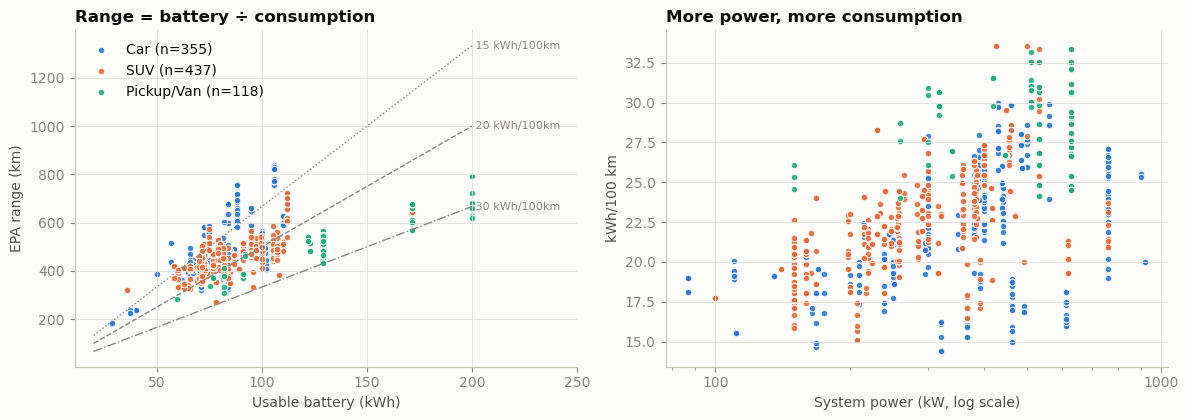

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
grp = bev_r["vclass"].where(bev_r["vclass"].isin(["Car", "SUV"]), "Pickup/Van")
for c, col in zip(["Car", "SUV", "Pickup/Van"], SERIES):
    s = bev_r[grp == c]
    axes[0].scatter(s["battery_net_kwh"], s["range_km"], s=22, color=col, edgecolor="#fcfcfb", linewidth=0.8, label=f"{c} (n={len(s)})", alpha=0.9)
    axes[1].scatter(s["power_kw"], s["elec_kwh_100km_comb"], s=22, color=col, edgecolor="#fcfcfb", linewidth=0.8, label=c, alpha=0.9)
xx = np.linspace(20, bev_r["battery_net_kwh"].max(), 50)
for eff_, ls in [(15, ":"), (20, "--"), (30, "-.")]:
    axes[0].plot(xx, xx / eff_ * 100, color=MUTED, lw=1, ls=ls)
    axes[0].text(xx[-1], xx[-1] / eff_ * 100, f" {eff_} kWh/100km", color=MUTED, fontsize=8, va="center")
axes[0].set(xlabel="Usable battery (kWh)", ylabel="EPA range (km)", title="Range = battery ÷ consumption")
axes[0].set_xlim(right=bev_r["battery_net_kwh"].max() * 1.25)
axes[1].set_xscale("log"); axes[1].xaxis.set_major_formatter(mticker.ScalarFormatter())
axes[1].set(xlabel="System power (kW, log scale)", ylabel="kWh/100 km", title="More power, more consumption")
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## Charging Connector Standards

unique trims: 634 | chi2 = 186.4, dof = 4, p = < 0.001, Cramér's V = 0.54


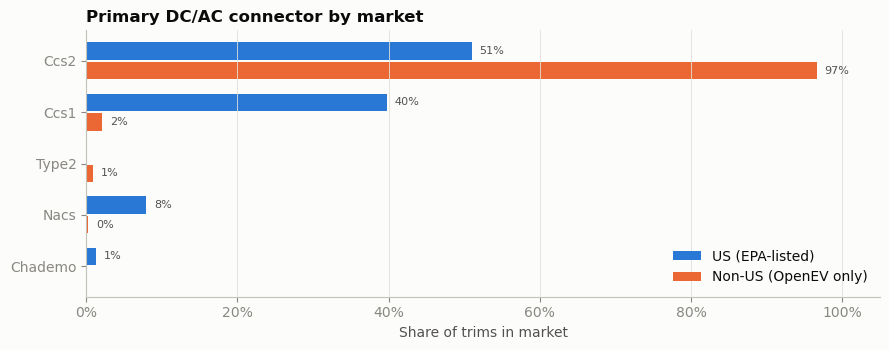

In [36]:
ev_u = (df[(df["powertrain"] == "BEV") & df["oe_unique_code"].notna()]
        .drop_duplicates("oe_unique_code")
        .assign(market=lambda d: np.where(d["source"].eq("OpenEV"), "Non-US (OpenEV only)", "US (EPA-listed)")))
ct_conn = pd.crosstab(ev_u["primary_connector"], ev_u["market"])
chi2, p, dof, v = cramers_v(ct_conn)
print(f"unique trims: {len(ev_u)} | chi2 = {chi2:.1f}, dof = {dof}, p = {fmt_p(p)}, Cramér's V = {v:.2f}")

share_conn = ct_conn.div(ct_conn.sum(), axis=1).sort_values("Non-US (OpenEV only)", ascending=True)

fig, ax = plt.subplots(figsize=(9, 3.6))
yy = np.arange(len(share_conn))
h = 0.38
for i, (mkt, col) in enumerate(zip(["US (EPA-listed)", "Non-US (OpenEV only)"], SERIES[:2])):
    ax.barh(yy + (h / 2 if i == 0 else -h / 2), share_conn[mkt], height=h - 0.04, color=col, label=mkt)
    for y_, v_ in zip(yy, share_conn[mkt]):
        if v_ > 0:
            ax.text(v_ + 0.01, y_ + (h / 2 if i == 0 else -h / 2), f"{v_:.0%}", va="center", fontsize=8, color=INK2)
ax.set_yticks(yy, share_conn.index); ax.set_xlim(0, 1.05)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set(xlabel="Share of trims in market", title="Primary DC/AC connector by market")
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

### 8.2 DC charging power, battery size and C-rate


Spearman rho(battery, DC kW) = 0.75, p = < 0.001, n = 605
C-rate by chemistry: Kruskal-Wallis H = 46.6, p = < 0.001, epsilon^2 = 0.077


,A,B,median_A,median_B,p_raw,cliffs_delta,p_holm,magnitude
0,lfp,nmc,1.562,2.174,0.000,-0.570,0.000,large
1,lfp,li-ion,1.562,2.000,0.000,-0.386,0.000,medium
2,nmc,li-ion,2.174,2.000,0.000,0.256,0.000,small


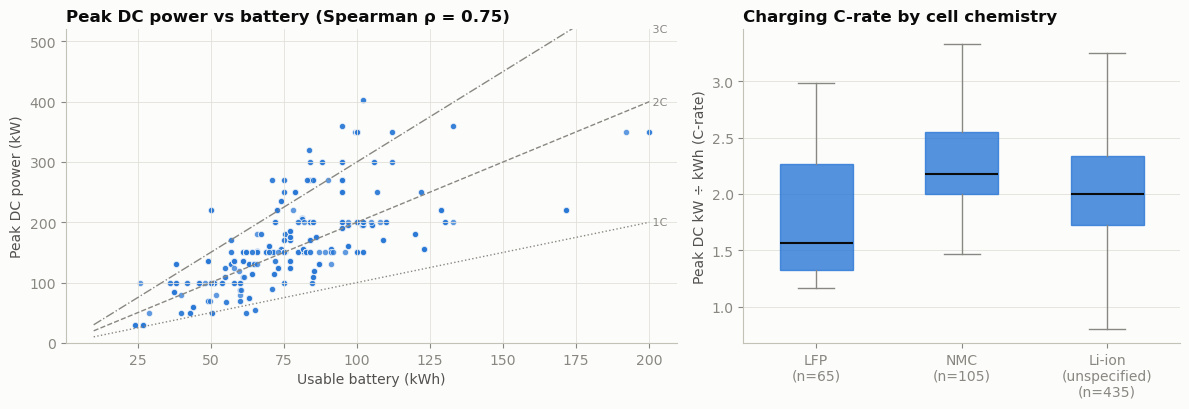

In [37]:
evc = ev_u.dropna(subset=["dc_max_kw", "battery_net_kwh"])
rho, p_rho = stats.spearmanr(evc["battery_net_kwh"], evc["dc_max_kw"])
print(f"Spearman rho(battery, DC kW) = {rho:.2f}, p = {fmt_p(p_rho)}, n = {len(evc)}")


chem = ["lfp", "nmc", "li-ion"]
H, p_c, e = kruskal_eps2([evc.loc[evc["battery_chemistry"] == c, "dc_c_rate"] for c in chem])
print(f"C-rate by chemistry: Kruskal-Wallis H = {H:.1f}, p = {fmt_p(p_c)}, epsilon^2 = {e:.3f}")

display(pairwise_mwu(evc.assign(battery_chemistry=evc["battery_chemistry"].astype(str)), "dc_c_rate", "battery_chemistry", chem).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
ax.scatter(evc["battery_net_kwh"], evc["dc_max_kw"], s=20, color=SERIES[0], alpha=0.75, edgecolor="#fcfcfb", linewidth=0.6)
xx = np.linspace(10, evc["battery_net_kwh"].max(), 50)
for c_, ls in [(1, ":"), (2, "--"), (3, "-.")]:
    ax.plot(xx, c_ * xx, color=MUTED, lw=1, ls=ls)
    ax.text(xx[-1], min(c_ * xx[-1], 520), f" {c_}C", color=MUTED, fontsize=8, va="center")
ax.set(xlabel="Usable battery (kWh)", ylabel="Peak DC power (kW)", ylim=(0, 520),
       title=f"Peak DC power vs battery (Spearman ρ = {rho:.2f})")
ax = axes[1]
data = [evc.loc[evc["battery_chemistry"] == c, "dc_c_rate"] for c in chem]
chem_lab = {"lfp": "LFP", "nmc": "NMC", "li-ion": "Li-ion\n(unspecified)"}
bp = ax.boxplot(data, tick_labels=[f"{chem_lab[c]}\n(n={len(d)})" for c, d in zip(chem, data)], patch_artist=True, widths=0.5,
                showfliers=False, medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch in bp["boxes"]:
    patch.set(facecolor=SERIES[0], edgecolor=SERIES[0], alpha=0.8)
ax.set(ylabel="Peak DC kW ÷ kWh (C-rate)", title="Charging C-rate by cell chemistry")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 8.3 Charging-stop time and "km gained per minute of charging"


In [38]:
evt = ev_u.dropna(subset=["dc_10_80_min_est", "km_per_charge_min"])
evt[["dc_10_80_min_est", "km_per_charge_min", "usable_range_km"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T.round(1)

,count,mean,std,min,10%,25%,50%,75%,90%,max
dc_10_80_min_est,605.000,30.600,9.300,13.600,19.000,24.800,30.000,35.000,42.700,74.400
km_per_charge_min,605.000,10.200,4.600,2.300,5.500,7.200,9.300,12.000,16.600,28.900
usable_range_km,605.000,281.700,76.900,108.200,183.900,231.500,280.500,327.700,369.300,581.300


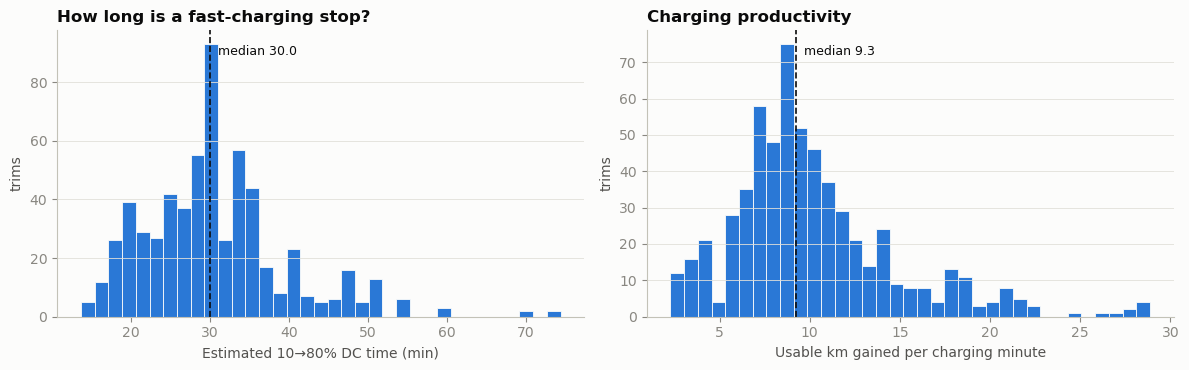

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, lab in [(axes[0], "dc_10_80_min_est", "Estimated 10→80% DC time (min)"),
                     (axes[1], "km_per_charge_min", "Usable km gained per charging minute")]:
    ax.hist(evt[col], bins=35, color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.6)
    ax.axvline(evt[col].median(), color=INK, ls="--", lw=1.2)
    ax.text(evt[col].median(), ax.get_ylim()[1] * 0.95, f"  median {evt[col].median():.1f}", fontsize=9, color=INK, va="top")
    ax.set(xlabel=lab, ylabel="trims"); ax.grid(axis="x", visible=False)
axes[0].set_title("How long is a fast-charging stop?"); axes[1].set_title("Charging productivity")
plt.tight_layout(); plt.show()

### Checking if EV can drive around Malaysia without recharging

In [40]:
CORRIDORS = {"KL → Ipoh": 205, "KL → Kuantan": 250, "KL → Johor Bahru": 330, "KL → Penang": 355, "KL → Kota Bharu": 460}
hw = meas[(meas["powertrain"] == "BEV") & meas["elec_kwh_100km_hwy"].notna()].copy()
hw["range_hwy_km"] = hw["range_km"] * hw["elec_kwh_100km_comb"] / hw["elec_kwh_100km_hwy"]

def stops_needed(rng_km, dist):
    first = 0.9 * rng_km
    return np.where(dist <= first, 0, np.ceil((dist - first) / (0.7 * rng_km)))

rows = []
for penalty, scen in [(1.0, "EPA highway"), (1.2, "+20% (110 km/h, A/C)")]:
    r = hw["range_hwy_km"] / penalty
    for name, dist in CORRIDORS.items():
        s = stops_needed(r, dist)
        rows.append({"scenario": scen, "corridor": name, "km": dist, "share_no_stop": (s == 0).mean(),
                     "median_stops": np.median(s), "share_≤1_stop": (s <= 1).mean()})
corr_tab = pd.DataFrame(rows)
print(f"BEVs analysed: {len(hw)} | median highway range = {hw['range_hwy_km'].median():.0f} km "
      f"(vs combined {hw['range_km'].median():.0f} km)")
corr_tab.pivot(index="corridor", columns="scenario", values=["share_no_stop", "share_≤1_stop"]).reindex(CORRIDORS).map("{:.0%}".format)

BEVs analysed: 1352 | median highway range = 428 km (vs combined 451 km)


share_no_stop                    share_≤1_stop            
scenario         +20% (110 km/h, A/C) EPA highway +20% (110 km/h, A/C) EPA highway
corridor                                                                          
KL → Ipoh                         94%         94%                  97%         98%
KL → Kuantan                      86%         94%                  96%         97%
KL → Johor Bahru                  44%         76%                  94%         95%
KL → Penang                       29%         66%                  94%         94%
KL → Kota Bharu                    4%         16%                  83%         94%

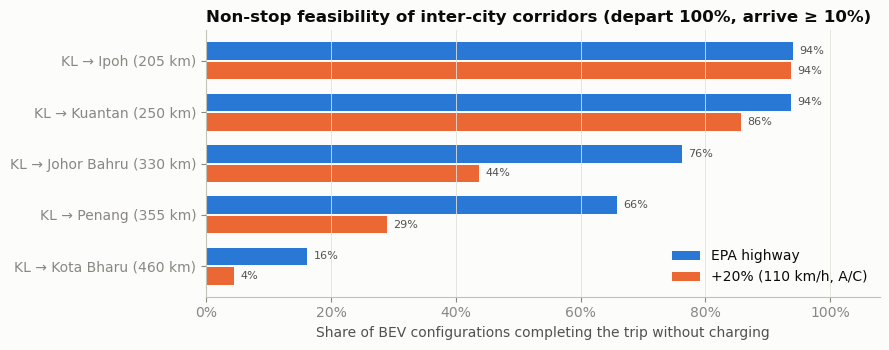

In [41]:
piv = corr_tab.pivot(index="corridor", columns="scenario", values="share_no_stop").reindex(CORRIDORS)
fig, ax = plt.subplots(figsize=(9, 3.6))
yy = np.arange(len(piv))[::-1]
for i, (scen, col) in enumerate(zip(["EPA highway", "+20% (110 km/h, A/C)"], SERIES[:2])):
    off = 0.19 if i == 0 else -0.19
    ax.barh(yy + off, piv[scen], height=0.34, color=col, label=scen)
    for y_, v_ in zip(yy, piv[scen]):
        ax.text(v_ + 0.01, y_ + off, f"{v_:.0%}", va="center", fontsize=8, color=INK2)
ax.set_yticks(yy, [f"{c} ({CORRIDORS[c]} km)" for c in piv.index]); ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1)); ax.grid(axis="y", visible=False)
ax.set(xlabel="Share of BEV configurations completing the trip without charging",
       title="Non-stop feasibility of inter-city corridors (depart 100%, arrive ≥ 10%)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

In [42]:
v_ = df.dropna(subset=["annual_fuel_cost_usd"])
rho_all, p_all = stats.spearmanr(v_["cost_myr_100km"], v_["annual_fuel_cost_usd"])
within = v_.groupby("powertrain", observed=True).apply(lambda g: stats.spearmanr(g["cost_myr_100km"], g["annual_fuel_cost_usd"])[0])
print(f"Spearman rho (all powertrains) = {rho_all:.3f}, p = {fmt_p(p_all)}")

within.rename("rho_within_powertrain").to_frame().T.round(3)

Spearman rho (all powertrains) = 0.978, p = < 0.001


powertrain,ICE,MHEV,HEV,PHEV,BEV
rho_within_powertrain,0.980,0.987,0.996,0.957,0.995


In [43]:
SUBSIDISED_RON95 = 1.99
bev_kwh = meas.loc[meas.powertrain == "BEV", "elec_kwh_100km_comb"].median()
hev_l = meas.loc[(meas.powertrain == "HEV") & (meas.fuel_grade == "Regular"), "fuel_l_100km_comb"].median()
ice_l = meas.loc[(meas.powertrain == "ICE") & (meas.fuel_grade == "Regular"), "fuel_l_100km_comb"].median()
share = np.linspace(0, 1, 101)
bev_cost = bev_kwh * (share * PRICE["elec_home"] + (1 - share) * PRICE["elec_dc"])
refs = {"ICE, RON95 market": ice_l * PRICE["RON95"], "ICE, RON95 subsidised": ice_l * SUBSIDISED_RON95,
        "HEV, RON95 market": hev_l * PRICE["RON95"], "HEV, RON95 subsidised": hev_l * SUBSIDISED_RON95}
print(f"median BEV = {bev_kwh:.1f} kWh/100km | median regular-fuel HEV = {hev_l:.2f} L/100km | ICE = {ice_l:.2f} L/100km")
breakeven = {k: (bev_kwh * PRICE["elec_dc"] - v) / (bev_kwh * (PRICE["elec_dc"] - PRICE["elec_home"])) for k, v in refs.items()}
charging_patterns = {"100% public DC": 0.0, f"base case ({A['HOME_CHARGING_SHARE']:.0%} home)": A["HOME_CHARGING_SHARE"], "100% home": 1.0}
display(pd.DataFrame({"median BEV, RM per 100 km": {k: bev_kwh * (s * PRICE["elec_home"] + (1 - s) * PRICE["elec_dc"])
                                                    for k, s in charging_patterns.items()}}).round(2))
pd.DataFrame({"cost_RM_per_100km": refs, "BEV_home_share_needed_to_match": breakeven}).assign(
    BEV_home_share_needed_to_match=lambda d: d["BEV_home_share_needed_to_match"].clip(0, 1)).round(3)

median BEV = 22.5 kWh/100km | median regular-fuel HEV = 5.88 L/100km | ICE = 10.23 L/100km


,"median BEV, RM per 100 km"
100% public DC,29.250
base case (70% home),15.860
100% home,10.120


,cost_RM_per_100km,BEV_home_share_needed_to_match
"ICE, RON95 market",38.862,0.000
"ICE, RON95 subsidised",20.351,0.465
"HEV, RON95 market",22.345,0.361
"HEV, RON95 subsidised",11.702,0.917


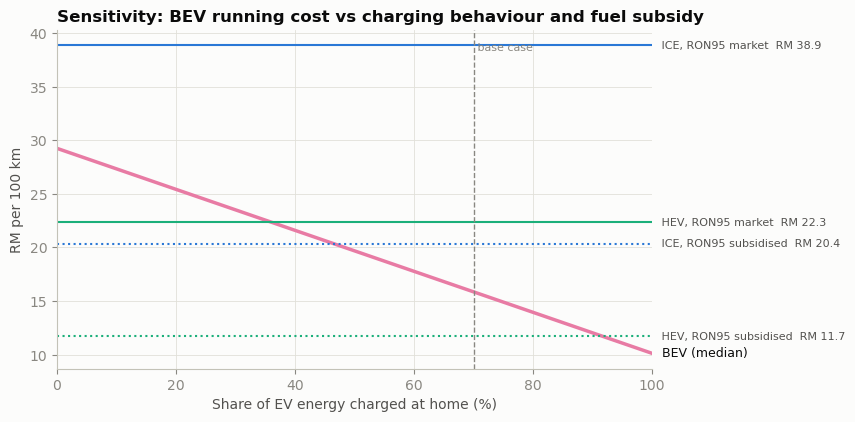

In [44]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(share * 100, bev_cost, color=PT_COLORS["BEV"], lw=2.5)
ax.text(101, bev_cost[-1], " BEV (median)", color=INK, fontsize=9, va="center")
for (k, v), col, ls in zip(refs.items(), [PT_COLORS["ICE"], PT_COLORS["ICE"], PT_COLORS["HEV"], PT_COLORS["HEV"]],
                           ["-", ":", "-", ":"]):
    ax.axhline(v, color=col, lw=1.5, ls=ls)
    ax.text(101, v, f" {k}  RM {v:.1f}", color=INK2, fontsize=8, va="center")
ax.axvline(A["HOME_CHARGING_SHARE"] * 100, color=MUTED, lw=1, ls="--")
ax.text(A["HOME_CHARGING_SHARE"] * 100, ax.get_ylim()[1] * 0.97, " base case", color=MUTED, fontsize=8, va="top")
ax.set(xlim=(0, 100), xlabel="Share of EV energy charged at home (%)", ylabel="RM per 100 km",
       title="Sensitivity: BEV running cost vs charging behaviour and fuel subsidy")
plt.subplots_adjust(right=0.72); plt.show()